<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/Emendas_PIX_RN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

emendas_pix = pd.read_csv('/content/export_PlanoAcao_1793229455028.csv', sep='|')

emendas_pix.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1833 entries, 0 to 1832
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Programa                       1833 non-null   object 
 1   Plano de Ação                  1833 non-null   object 
 2   Parceria                       0 non-null      float64
 3   UF                             1833 non-null   object 
 4   Número da Emenda               1833 non-null   int64  
 5   Nome do Parlamentar            1833 non-null   object 
 6   CNPJ do Beneficiário           1833 non-null   int64  
 7   Beneficiário                   1833 non-null   object 
 8   Valor Custeio                  1833 non-null   object 
 9   Valor Investimento             1833 non-null   object 
 10  Situação do Plano de Ação      1833 non-null   object 
 11  Motivo do Impedimento          102 non-null    object 
 12  Situação do Plano de Trabalho  1774 non-null   o

### 1. Estatística Descritiva dos Valores


In [ ]:
# Exibindo estatísticas descritivas dos valores numéricos
estatisticas_valores = emendas_pix[['Valor Custeio Num', 'Valor Investimento Num', 'Valor Total Num']].describe()
display(estatisticas_valores)

,Valor Custeio Num,Valor Investimento Num,Valor Total Num
count,1.833000e+03,1.833000e+03,1.833000e+03
mean,5.958040e+04,4.367701e+05,4.963505e+05
std,2.616441e+05,5.481081e+05,5.823216e+05
min,0.000000e+00,0.000000e+00,1.000000e+03
25%,0.000000e+00,1.980000e+05,2.300000e+05
50%,0.000000e+00,3.960000e+05,3.960000e+05
75%,0.000000e+00,4.975000e+05,5.000000e+05
max,4.720713e+06,7.489107e+06,7.489107e+06


### 2. Distribuição de Recursos por Beneficiário (Municípios / Entidades)
Análise para entender quais municípios ou entidades do RN estão recebendo o maior volume total financeiro das emendas Pix.

In [ ]:
# Padronizando os nomes dos beneficiários para maiúsculas para evitar duplicidades
emendas_pix['Beneficiario'] = emendas_pix['Beneficiário'].str.upper().str.strip()

# Agrupando recursos totais por Beneficiário
recursos_por_beneficiario = emendas_pix.groupby('Beneficiario')['Valor Total Num'].agg(['sum', 'count', 'mean']).sort_values(by='sum', ascending=False)
recursos_por_beneficiario.columns = ['Valor Total Acumulado (R$)', 'Quantidade de Emendas', 'Valor Médio (R$)']

# Exibindo os 20 maiores beneficiários
display(recursos_por_beneficiario.head(20))

,Valor Total Acumulado (R$),Quantidade de Emendas,Valor Médio (R$)
Beneficiario,,,
ESTADO DO RIO GRANDE DO NORTE,46494736.86,54,8.610136e+05
MUNICIPIO DE NATAL,33789863.08,45,7.508858e+05
MUNICIPIO DE CEARA-MIRIM,27058660.92,19,1.424140e+06
MUNICIPIO DE MACAIBA,24810634.00,35,7.088753e+05
MUNICIPIO DE CAICO,24000746.00,43,5.581569e+05
MUNICIPIO DE TOUROS,21841467.62,20,1.092073e+06
MUNICIPIO DE ACARI,17962749.00,23,7.809891e+05
MUNICIPIO DE EXTREMOZ,17203270.00,21,8.192033e+05
MUNICIPIO DE ITAJA,16740123.62,20,8.370062e+05


### 2.1. Gráfico de Barras
Exibe os 10 beneficiários que receberam o maior volume financeiro total acumulado no estado.

/tmp/ipykernel_733/951109786.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


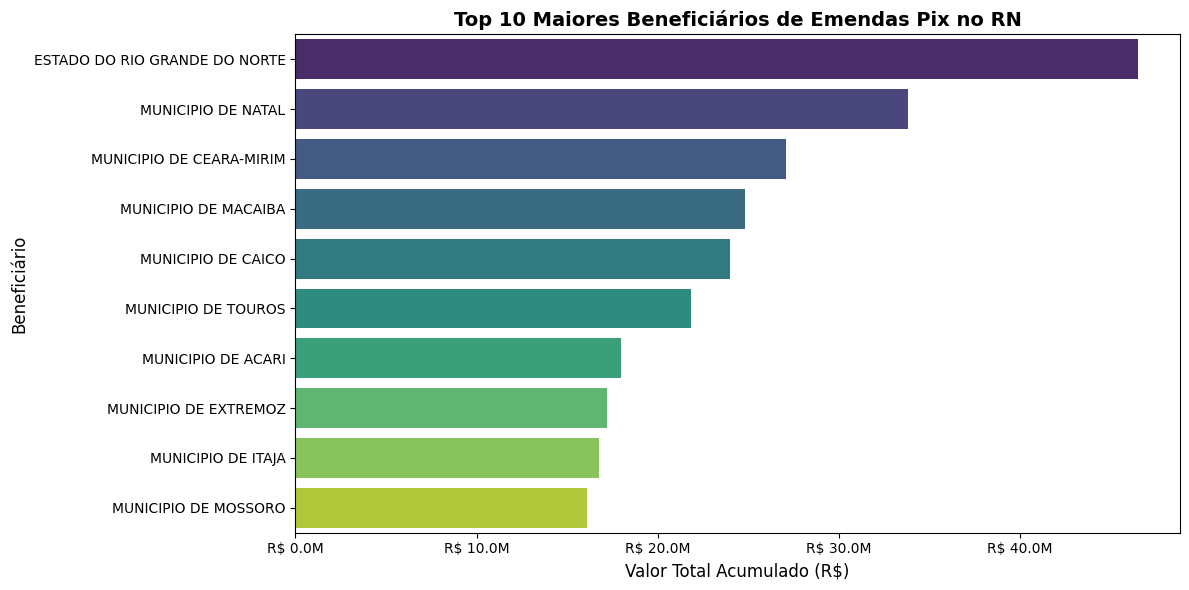

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionando os 10 maiores beneficiários
top_10_beneficiarios = recursos_por_beneficiario.head(10).reset_index()

# Definindo o estilo e tamanho do gráfico
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Valor Total Acumulado (R$)',
    y='Beneficiario',
    data=top_10_beneficiarios,
    palette='viridis'
)

# Configurações de títulos e rótulos
plt.title('Top 10 Maiores Beneficiários de Emendas Pix no RN', fontsize=14, fontweight='bold')
plt.xlabel('Valor Total Acumulado (R$)', fontsize=12)
plt.ylabel('Beneficiário', fontsize=12)

# Formatação dos valores do eixo X para facilitar a leitura (em milhões)
import matplotlib.ticker as ticker
formatter = ticker.FuncFormatter(lambda x, pos: f'R$ {x*1e-6:.1f}M')
plt.gca().xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

### 3. Maiores Destinações por Parlamentar
Agrupamento corrigindo as variações de nomes em maiúsculas e minúsculas para consolidar o real valor destinado por cada parlamentar.

In [ ]:
# Padronizando os nomes dos parlamentares para maiúsculas
emendas_pix['Nome Parlamentar'] = emendas_pix['Nome do Parlamentar'].str.upper().str.strip()

# Agrupando e somando os valores por parlamentar
parlamentar_consolidado = emendas_pix.groupby('Nome Parlamentar')['Valor Total Num'].agg(['sum', 'count']).sort_values(by='sum', ascending=False)
parlamentar_consolidado.columns = ['Valor Total Destinado (R$)', 'Quantidade de Emendas']
display(parlamentar_consolidado.head(15))

,Valor Total Destinado (R$),Quantidade de Emendas
Nome Parlamentar,,
STYVENSON VALENTIM,1.316554e+08,180
ZENAIDE MAIA,1.264729e+08,158
ROGÉRIO MARINHO,8.623386e+07,200
BENES LEOCÁDIO,8.427794e+07,238
JOÃO MAIA,8.230732e+07,169
ROBINSON FARIA,6.227525e+07,78
GENERAL GIRÃO,6.092440e+07,218
SARGENTO GONÇALVES,4.237253e+07,89
NATÁLIA BONAVIDES,4.234984e+07,87


### 3.1 Parlamentares por Recursos Destinados
Este gráfico compara o montante total de recursos indicados pelos 10 parlamentares com maior participação financeira nas emendas Pix do estado.

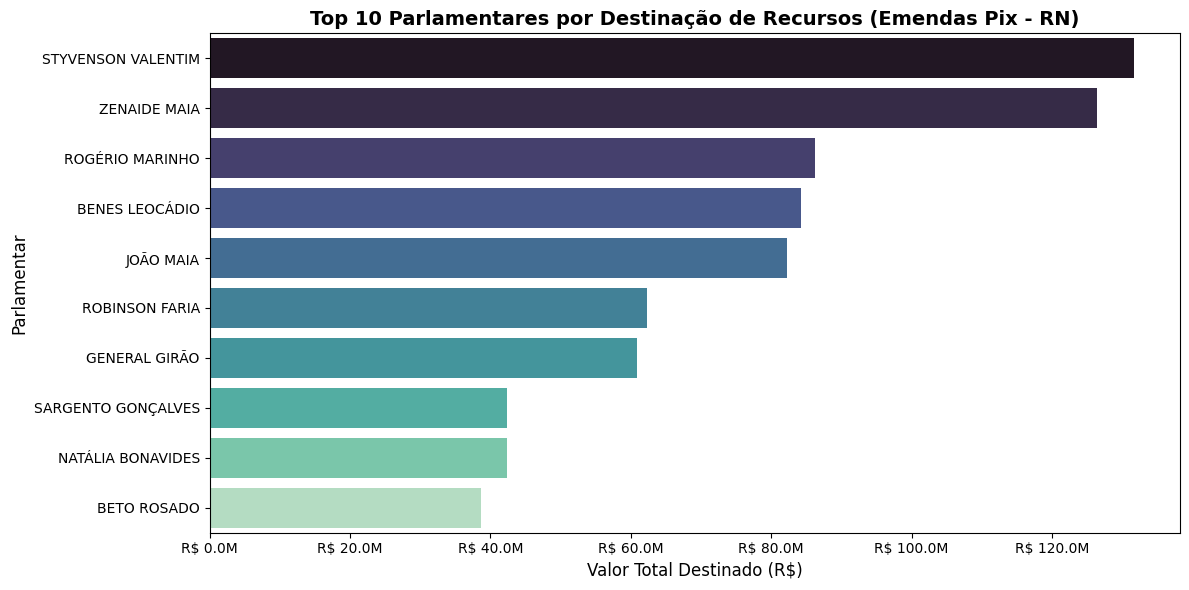

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker

# Selecionando os 10 parlamentares com maior destinação
top_10_parlamentares = parlamentar_consolidado.head(10).reset_index()

# Definindo o estilo e tamanho do gráfico
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Valor Total Destinado (R$)',
    y='Nome Parlamentar',
    data=top_10_parlamentares,
    palette='mako',
    hue='Nome Parlamentar',
    legend=False
)

# Configurações de títulos e rótulos
plt.title('Top 10 Parlamentares por Destinação de Recursos (Emendas Pix - RN)', fontsize=14, fontweight='bold')
plt.xlabel('Valor Total Destinado (R$)', fontsize=12)
plt.ylabel('Parlamentar', fontsize=12)

# Formatação do eixo X para milhões
formatter = ticker.FuncFormatter(lambda x, pos: f'R$ {x*1e-6:.1f}M')
plt.gca().xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()